In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240226_CAT16_C10_W3_run2.DSC", exp_type="francklab_esr/romana") #W3 heating
d2 = find_file("240226_CAT16_C10_W20_run2.DSC", exp_type="francklab_esr/romana") #W20 heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'CAT16 w$_0= 3$ in Dodecane for heating')

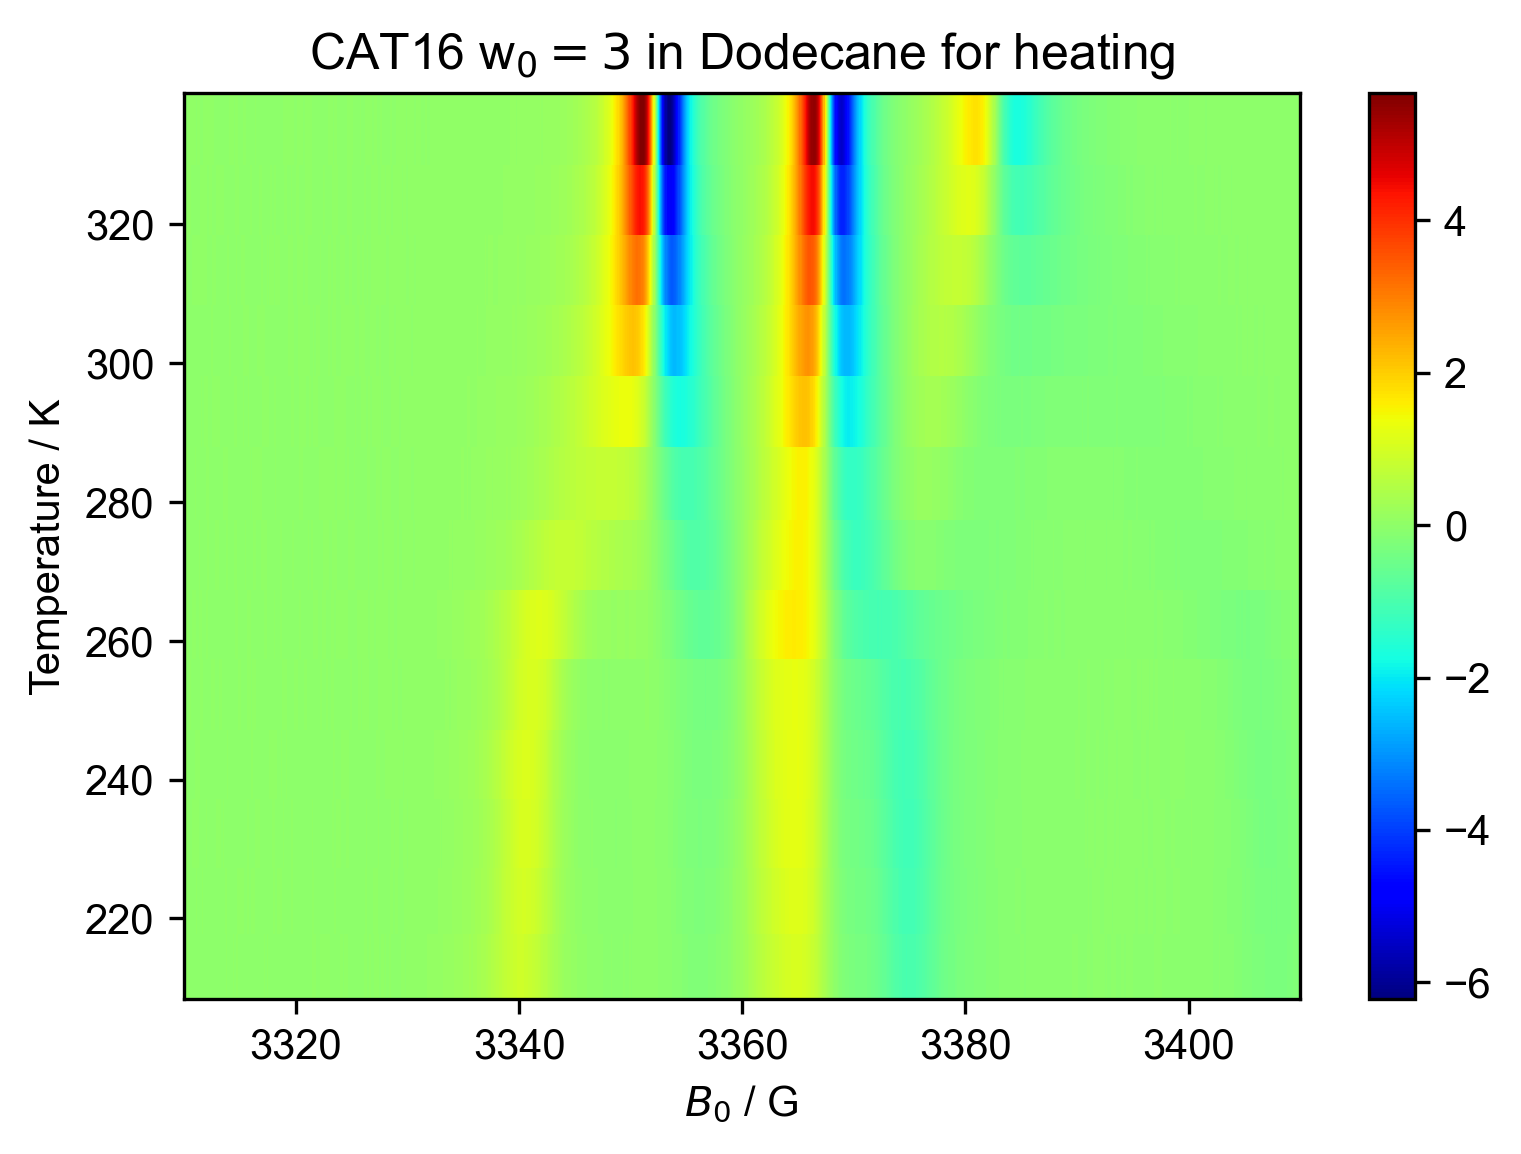

In [7]:
# W3
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1=d1['$B_0$':(3310, 3410)]
d1.sort('Temperature')
# d1.pcolor()
d1.reorder("Temperature").pcolor()
title("CAT16 w$_0= 3$ in Dodecane for heating")

Text(0.5, 1.0, 'CAT16 w$_0$= 20 in Dodecane for heating')

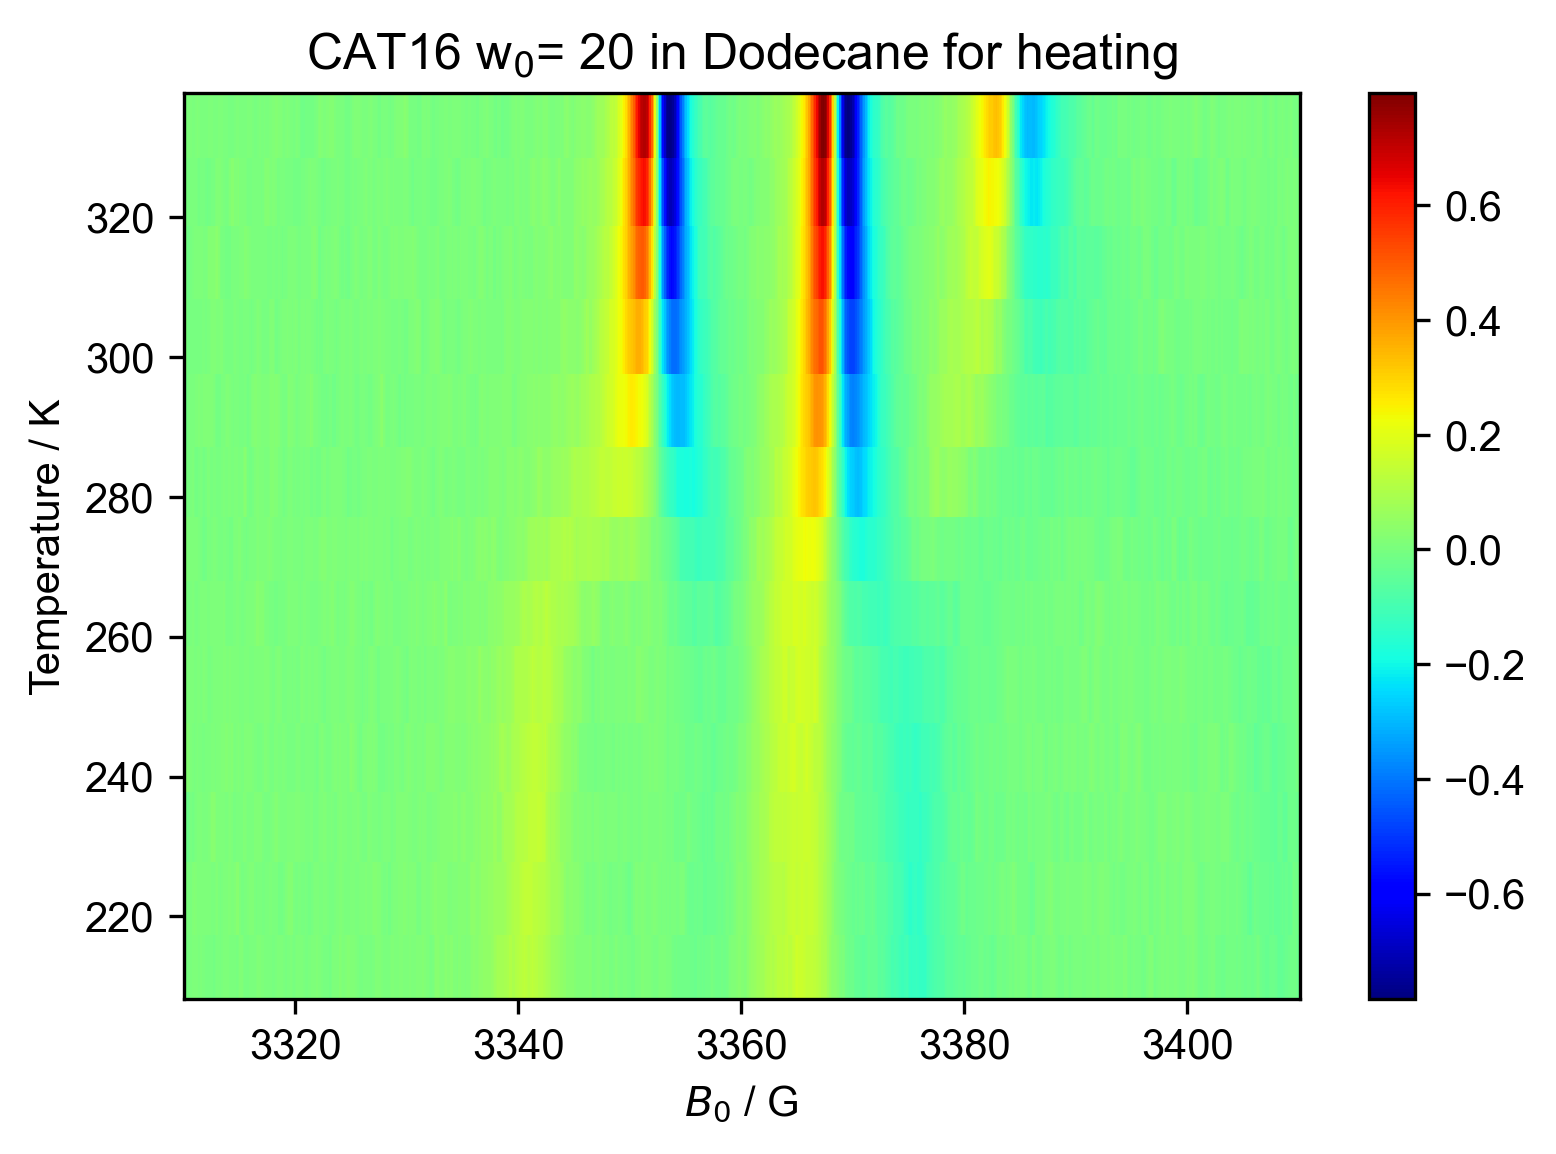

In [8]:
#w20
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2=d2['$B_0$':(3310, 3410)]
d2.sort('Temperature')
#d2.pcolor()
d2.reorder("Temperature").pcolor()
title("CAT16 w$_0$= 20 in Dodecane for heating")

From this, I learn that
it's easiest to show the 1D plots above and below the transition

In [9]:
# #w3
# for this_label, temp_range in [
#     ("below transition", (None, 257.8)),
#     ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure() # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

In [10]:
# #w3 same plot
# for this_label, temp_range in [
#     ("All transition", (173, 373))
#  #   ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure() # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

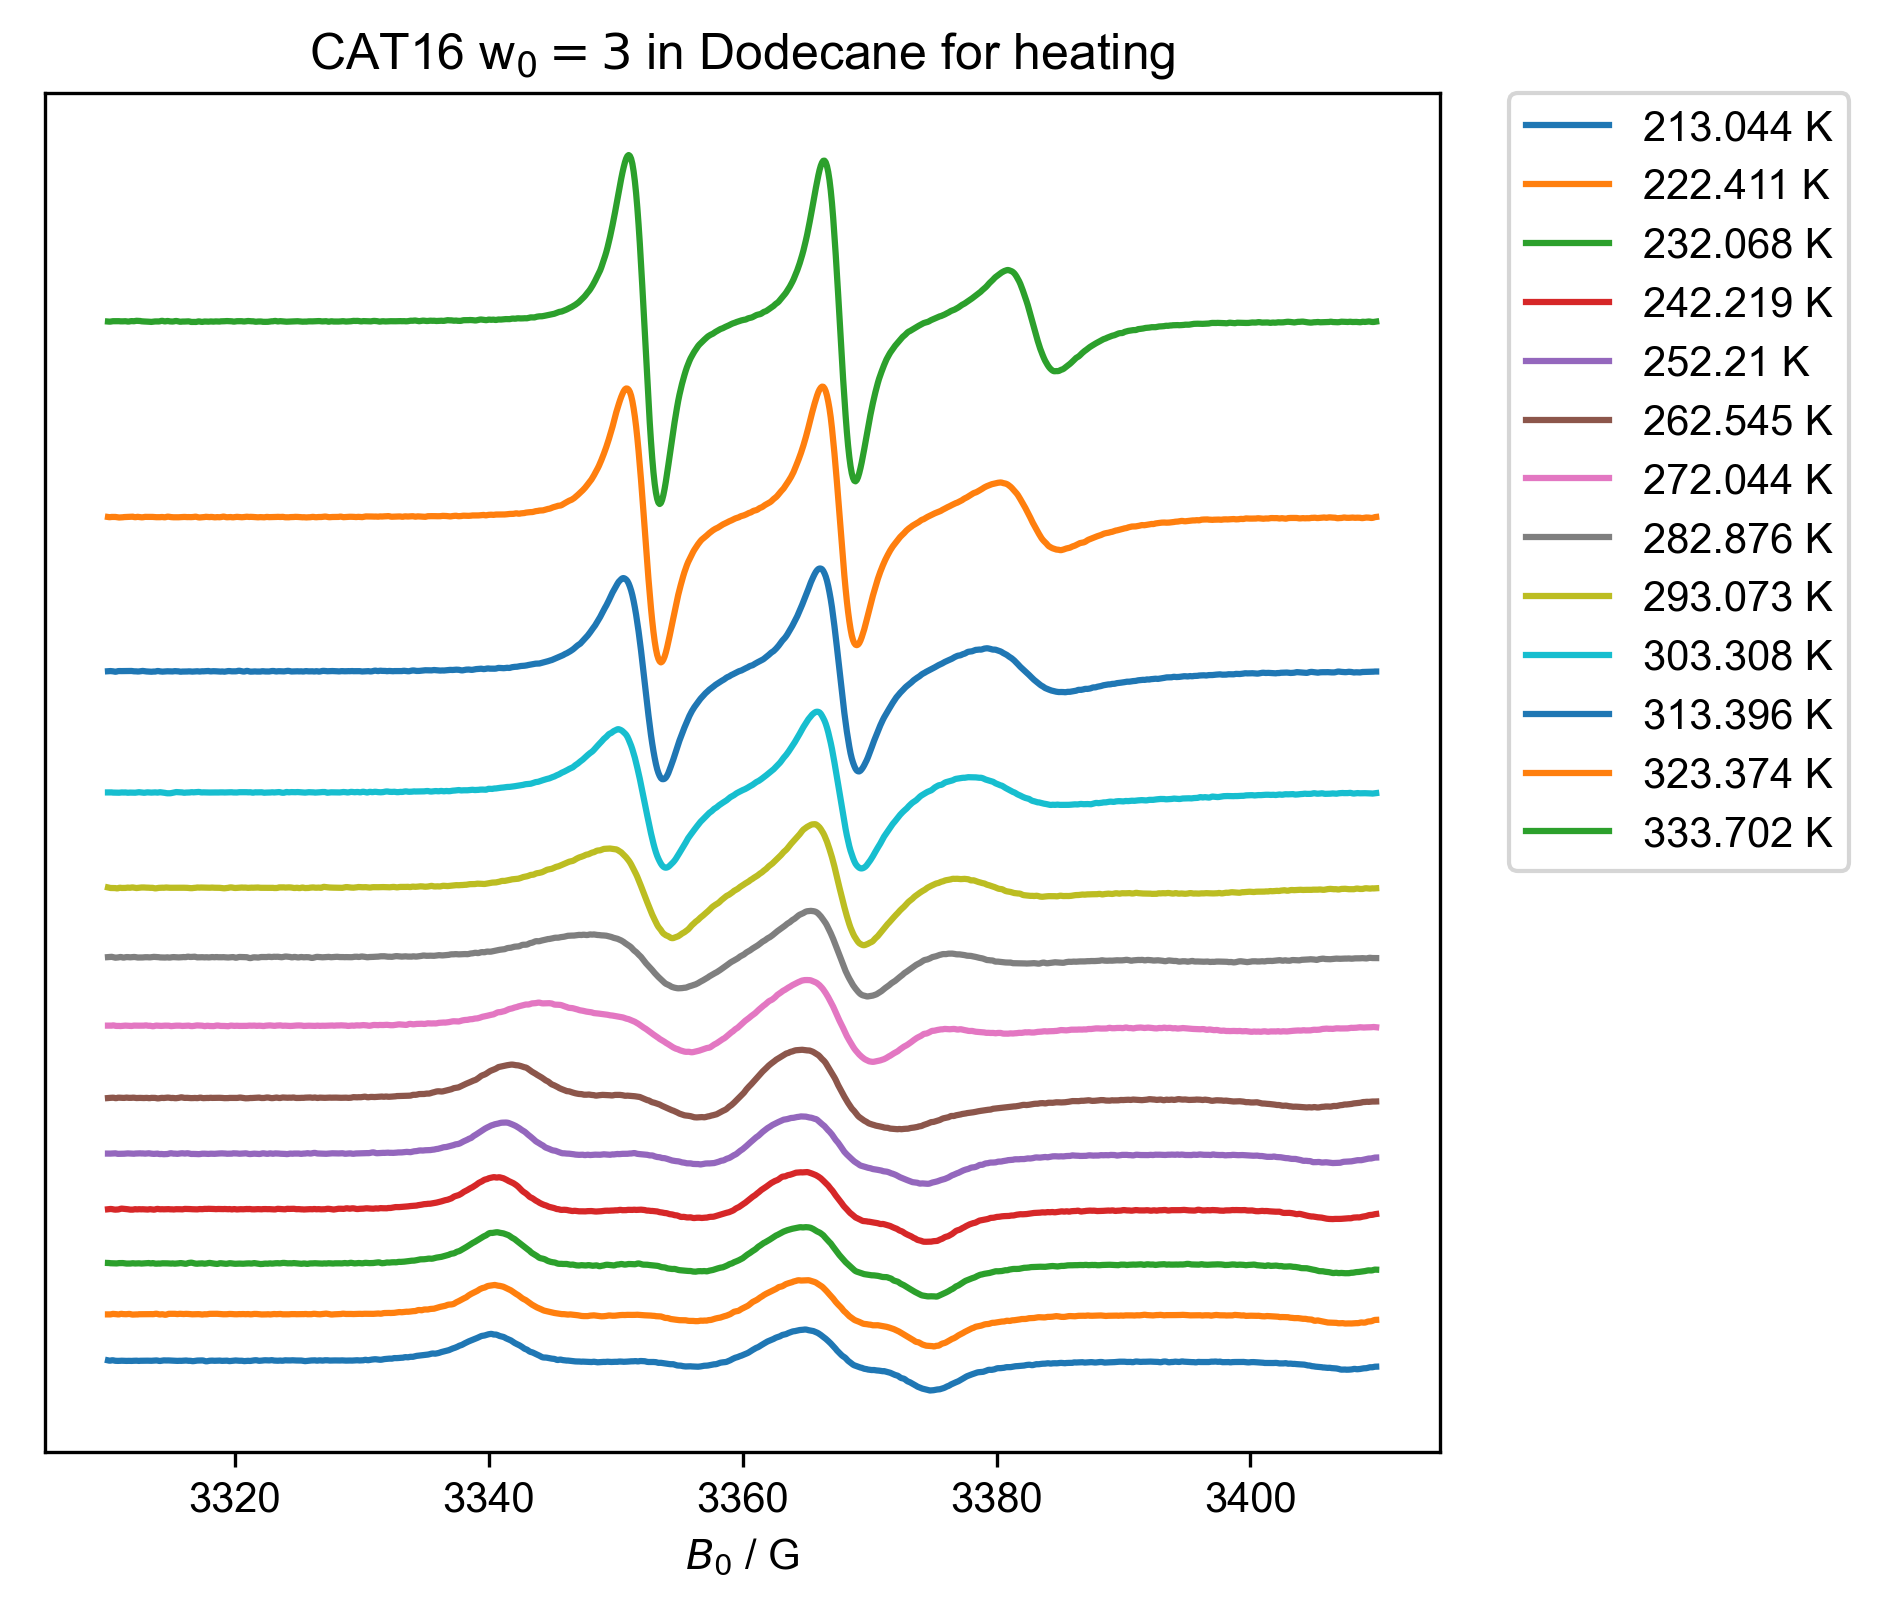

In [11]:
#w3 same plot in offset
offset= 0

for this_label, temp_range in [
    ("CAT16 w$_0= 3$ in Dodecane for heating", (173, 373))
 #   ("above transition", (258, None)),
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi= 300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#       offset += 2
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

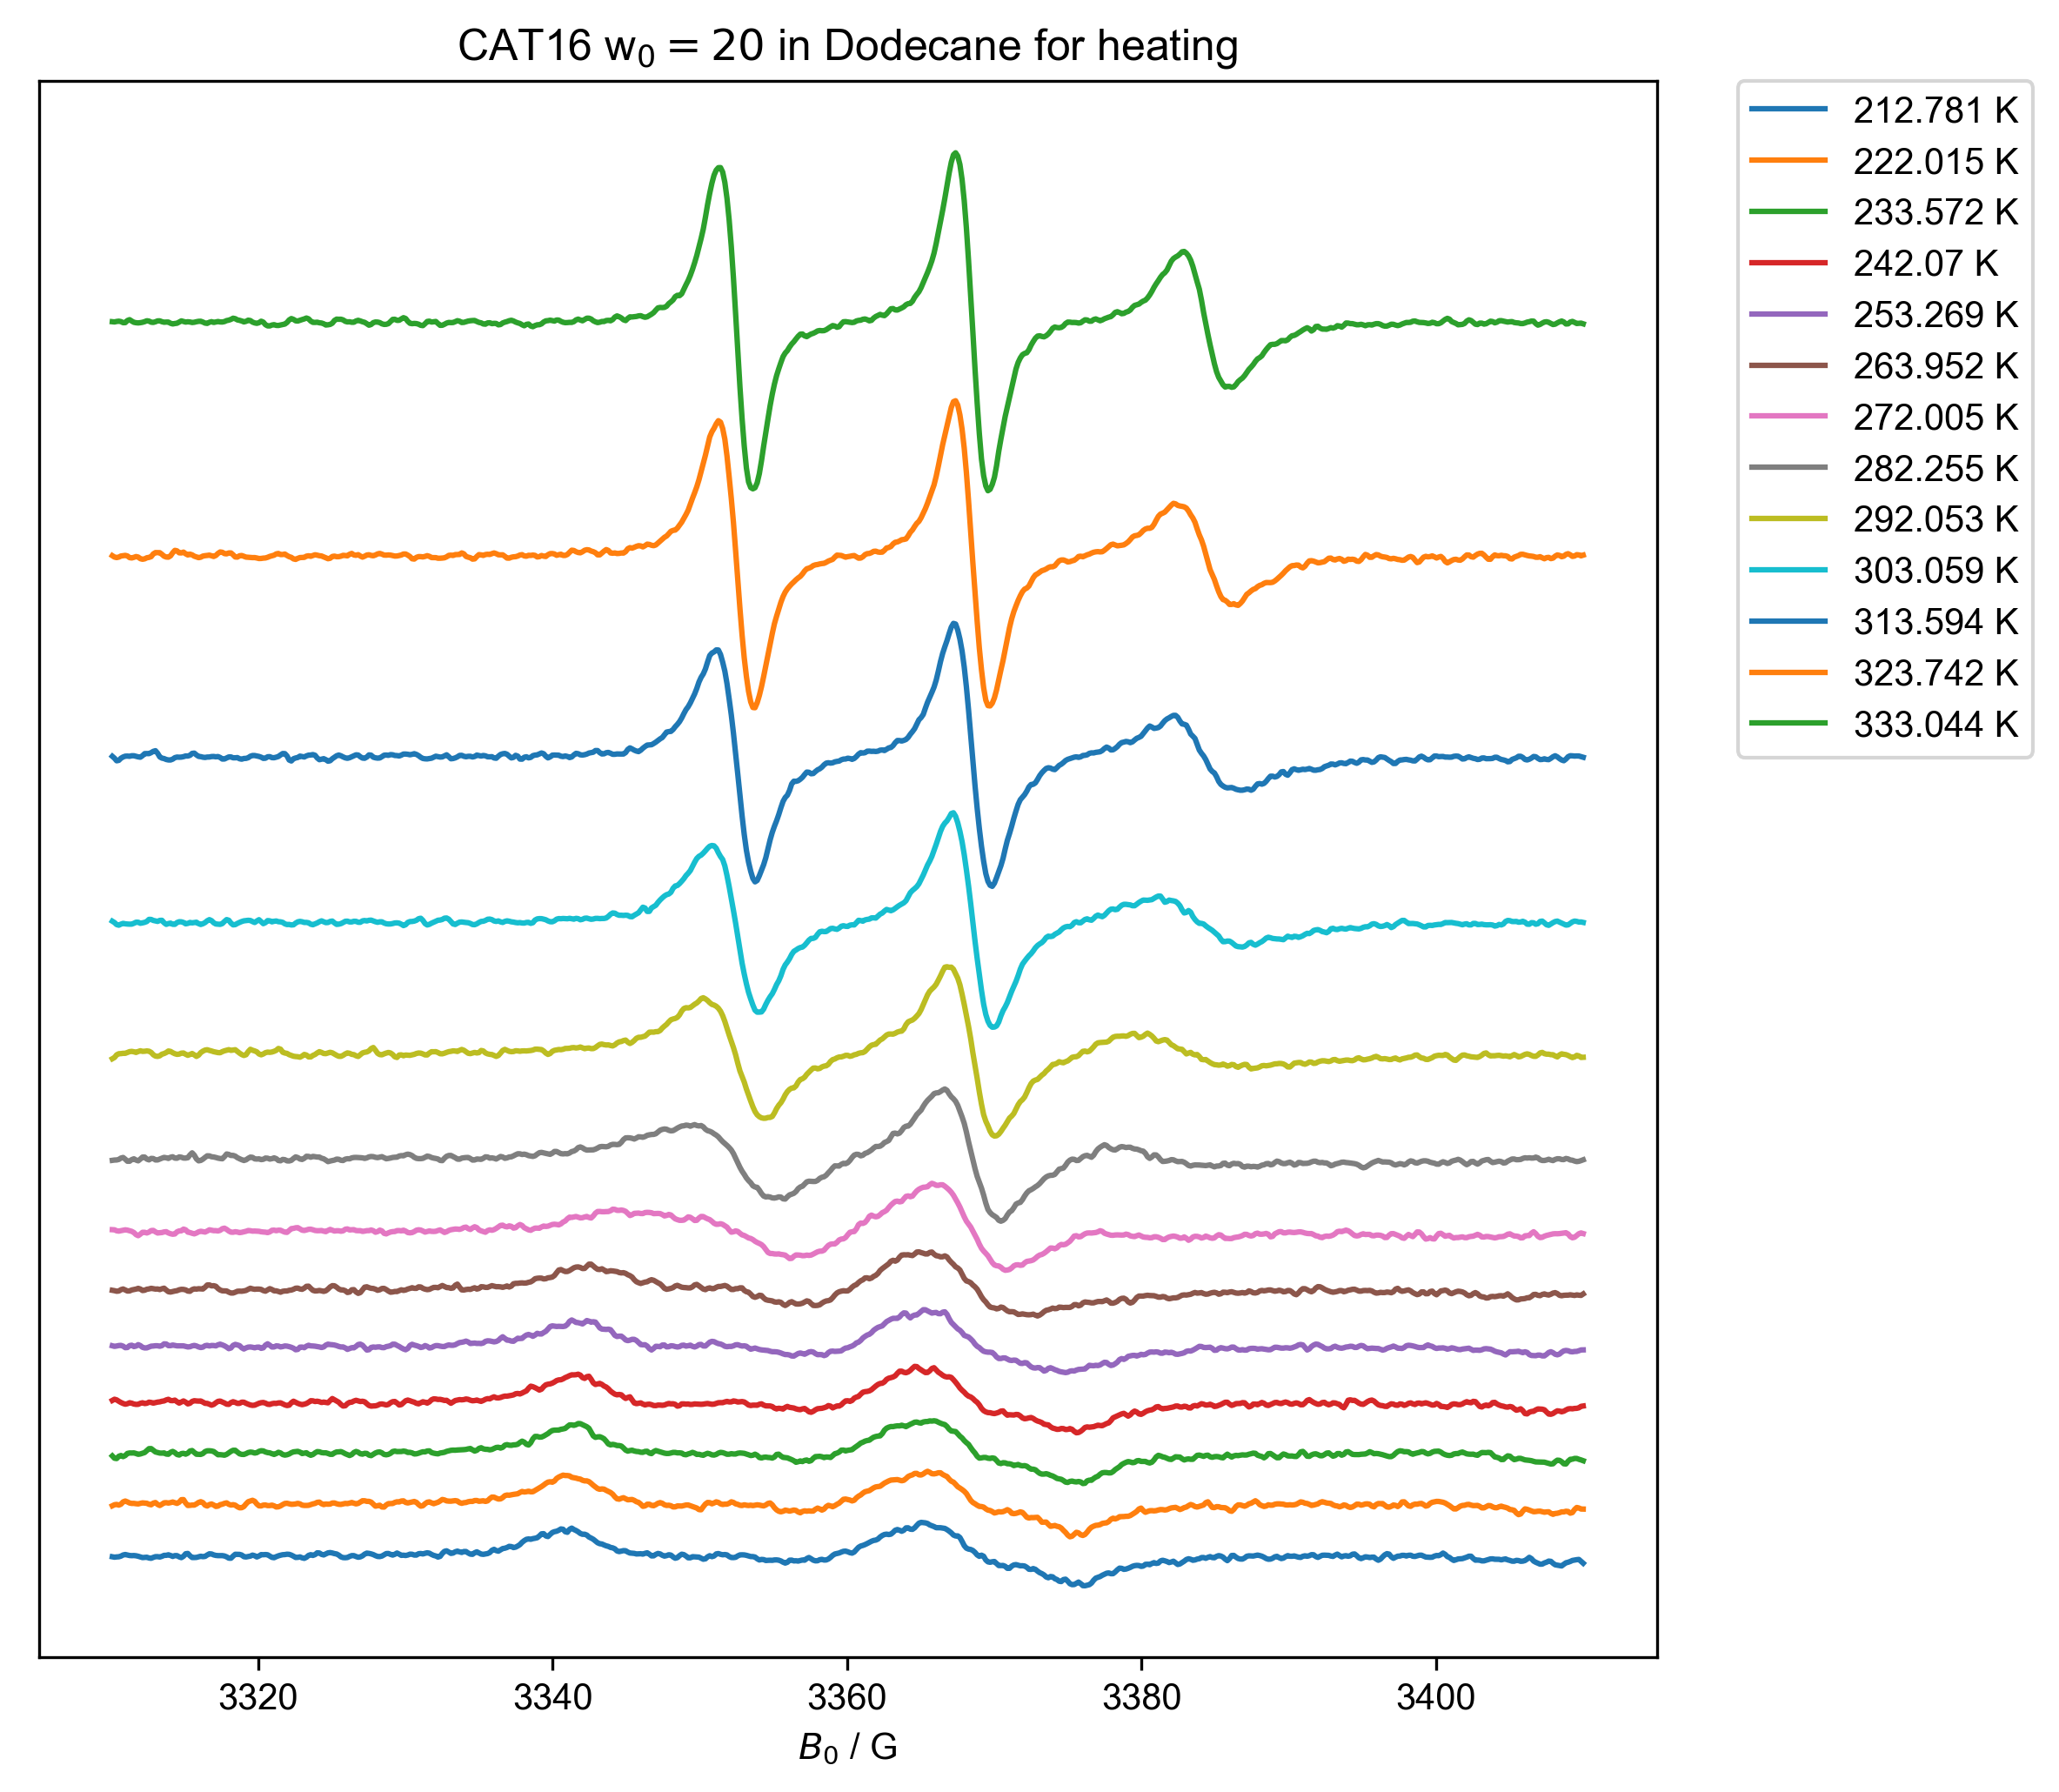

In [12]:
#w20 same plot in offset
offset= 0

for this_label, temp_range in [
    ("CAT16 w$_0= 20$ in Dodecane for heating", (173, 373))
 ]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 5
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

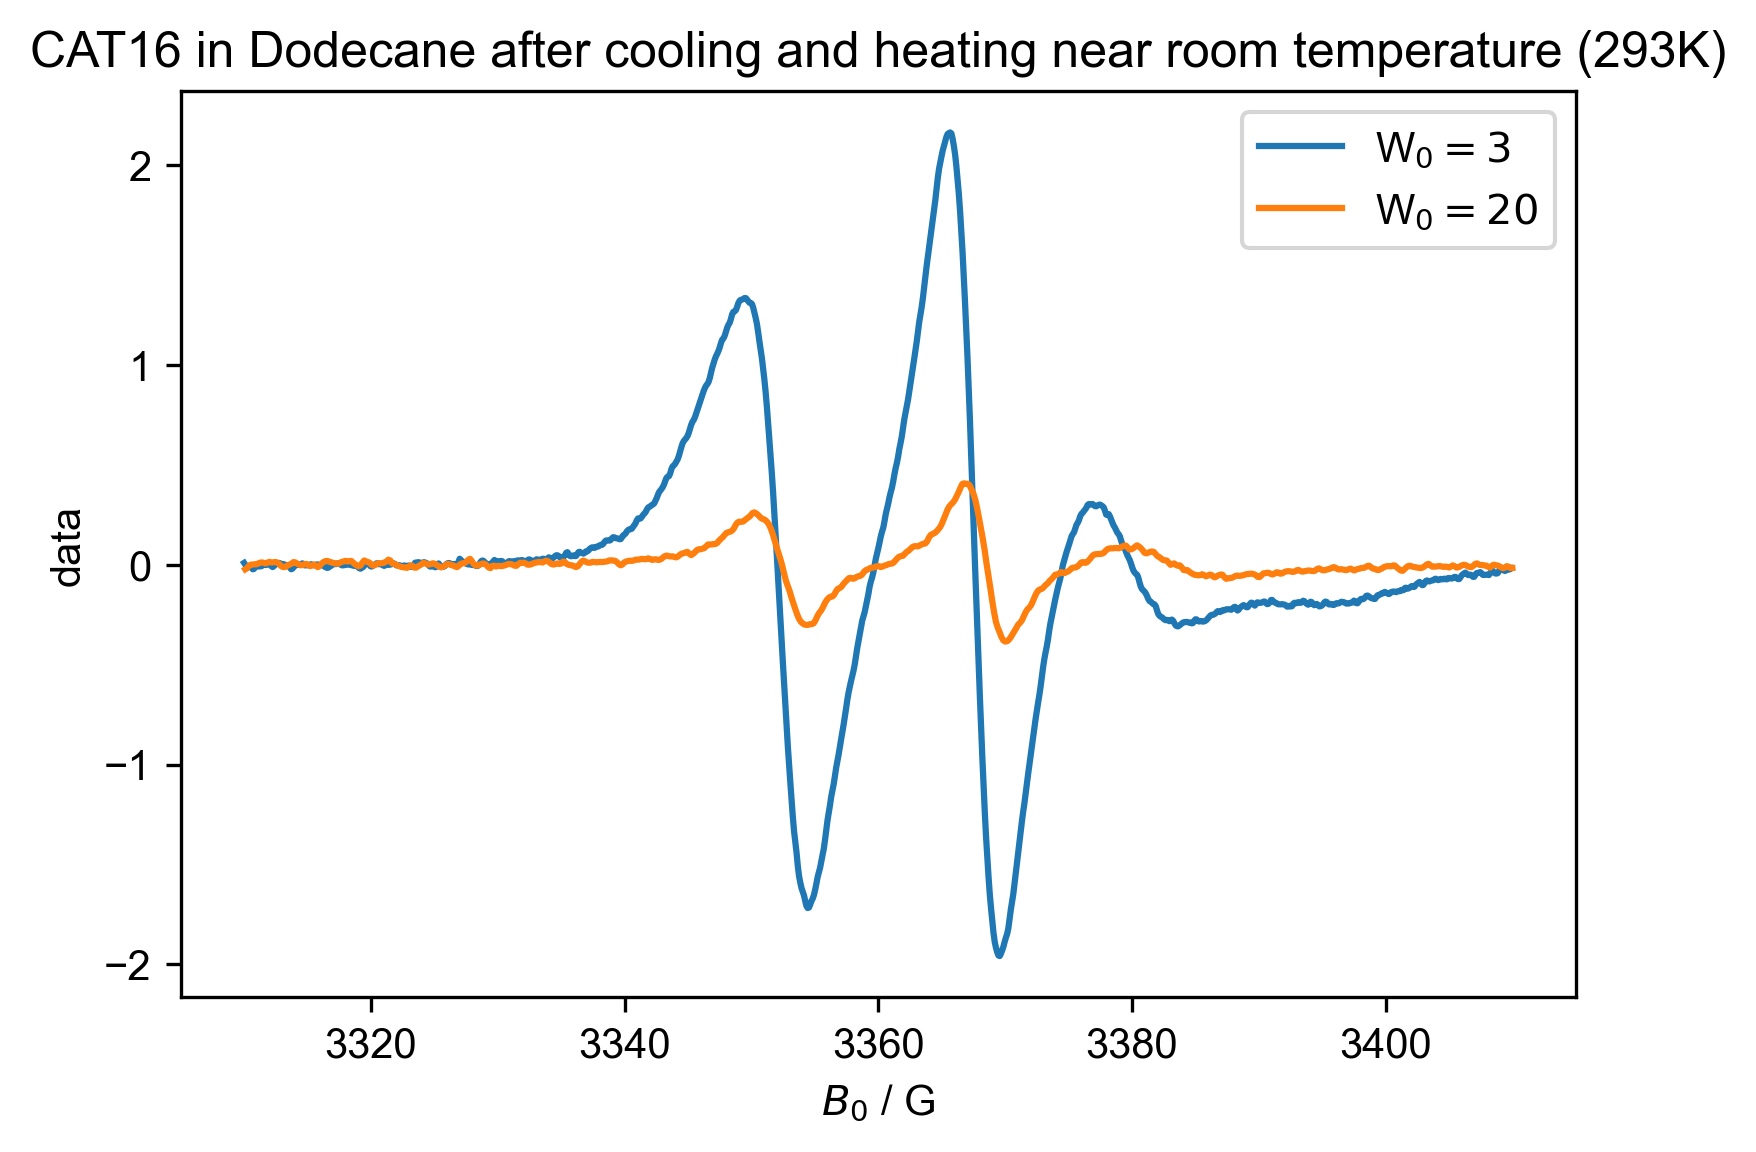

In [13]:
#near room temperature
#print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":293], label="W$_0=3$")
plot(d2["Temperature":293], label="W$_0=20$")
title("CAT16 in Dodecane after cooling and heating near room temperature (293K)")
legend()

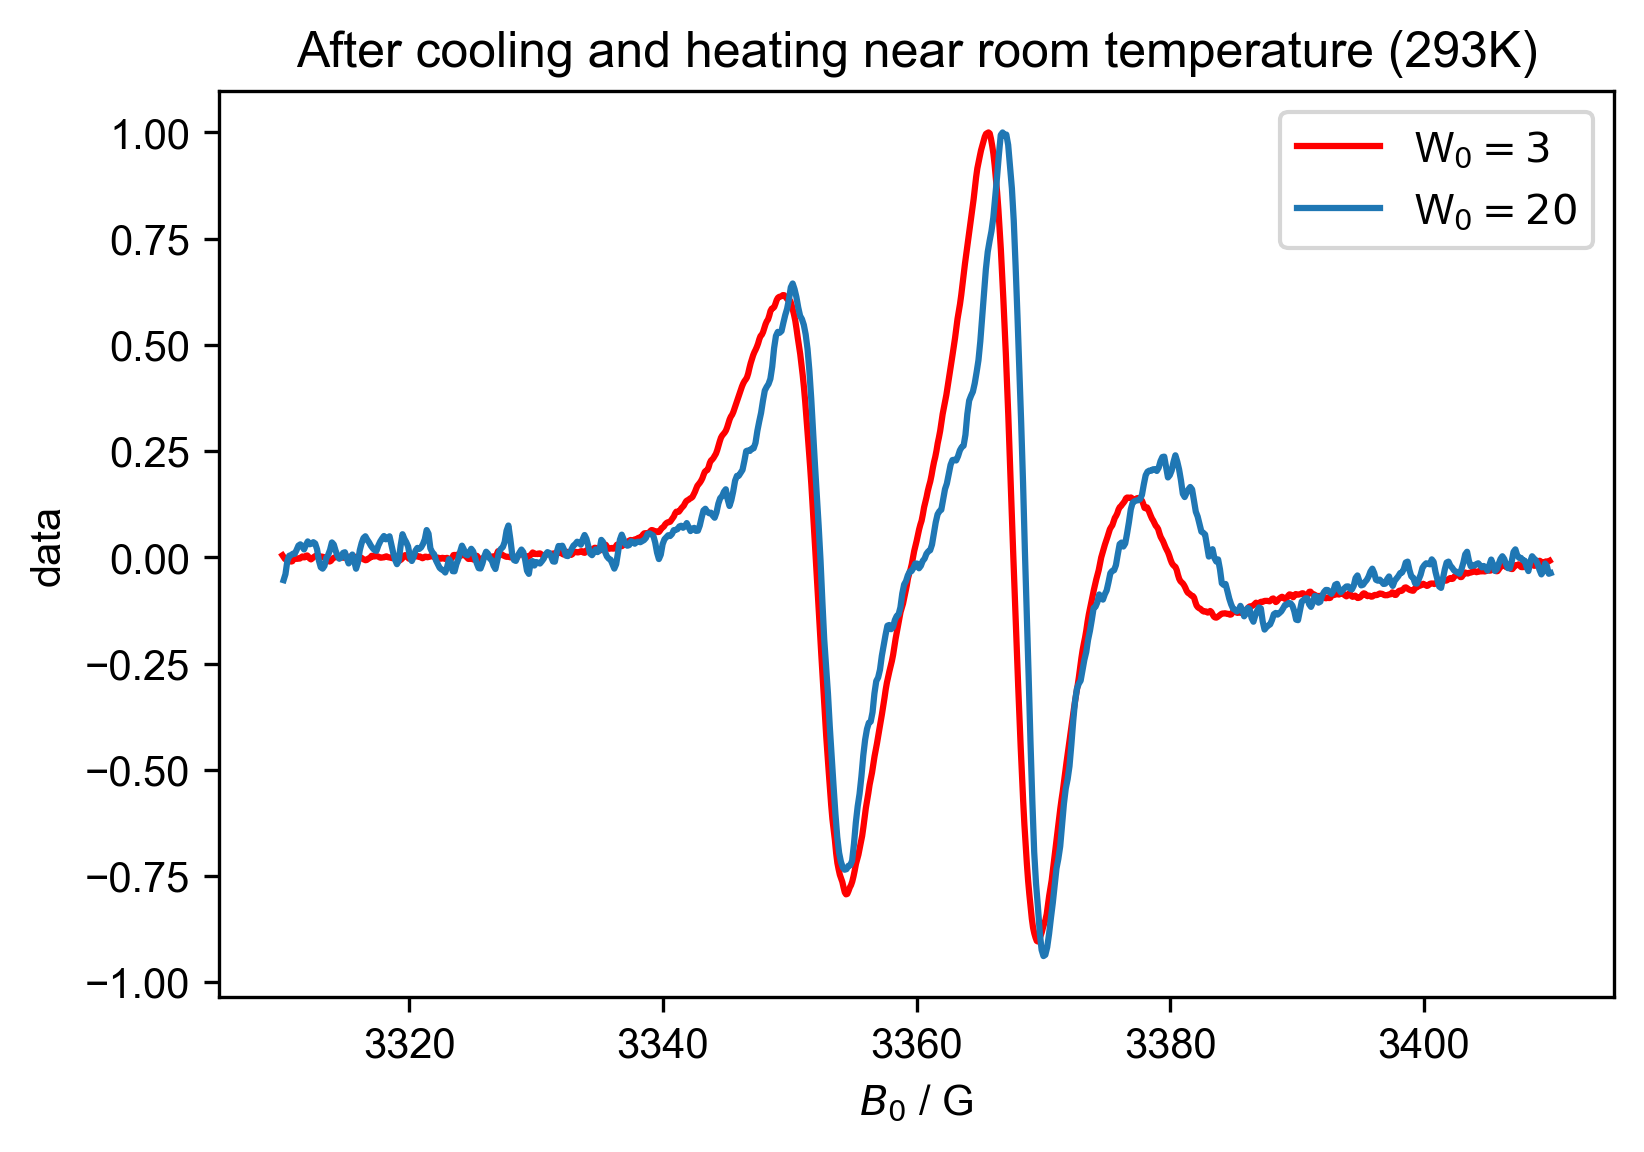

In [14]:
#Normalized
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "W$_0=3$", color="red")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "W$_0=20$")
title("After cooling and reheating near room temperature (293K)")
legend()

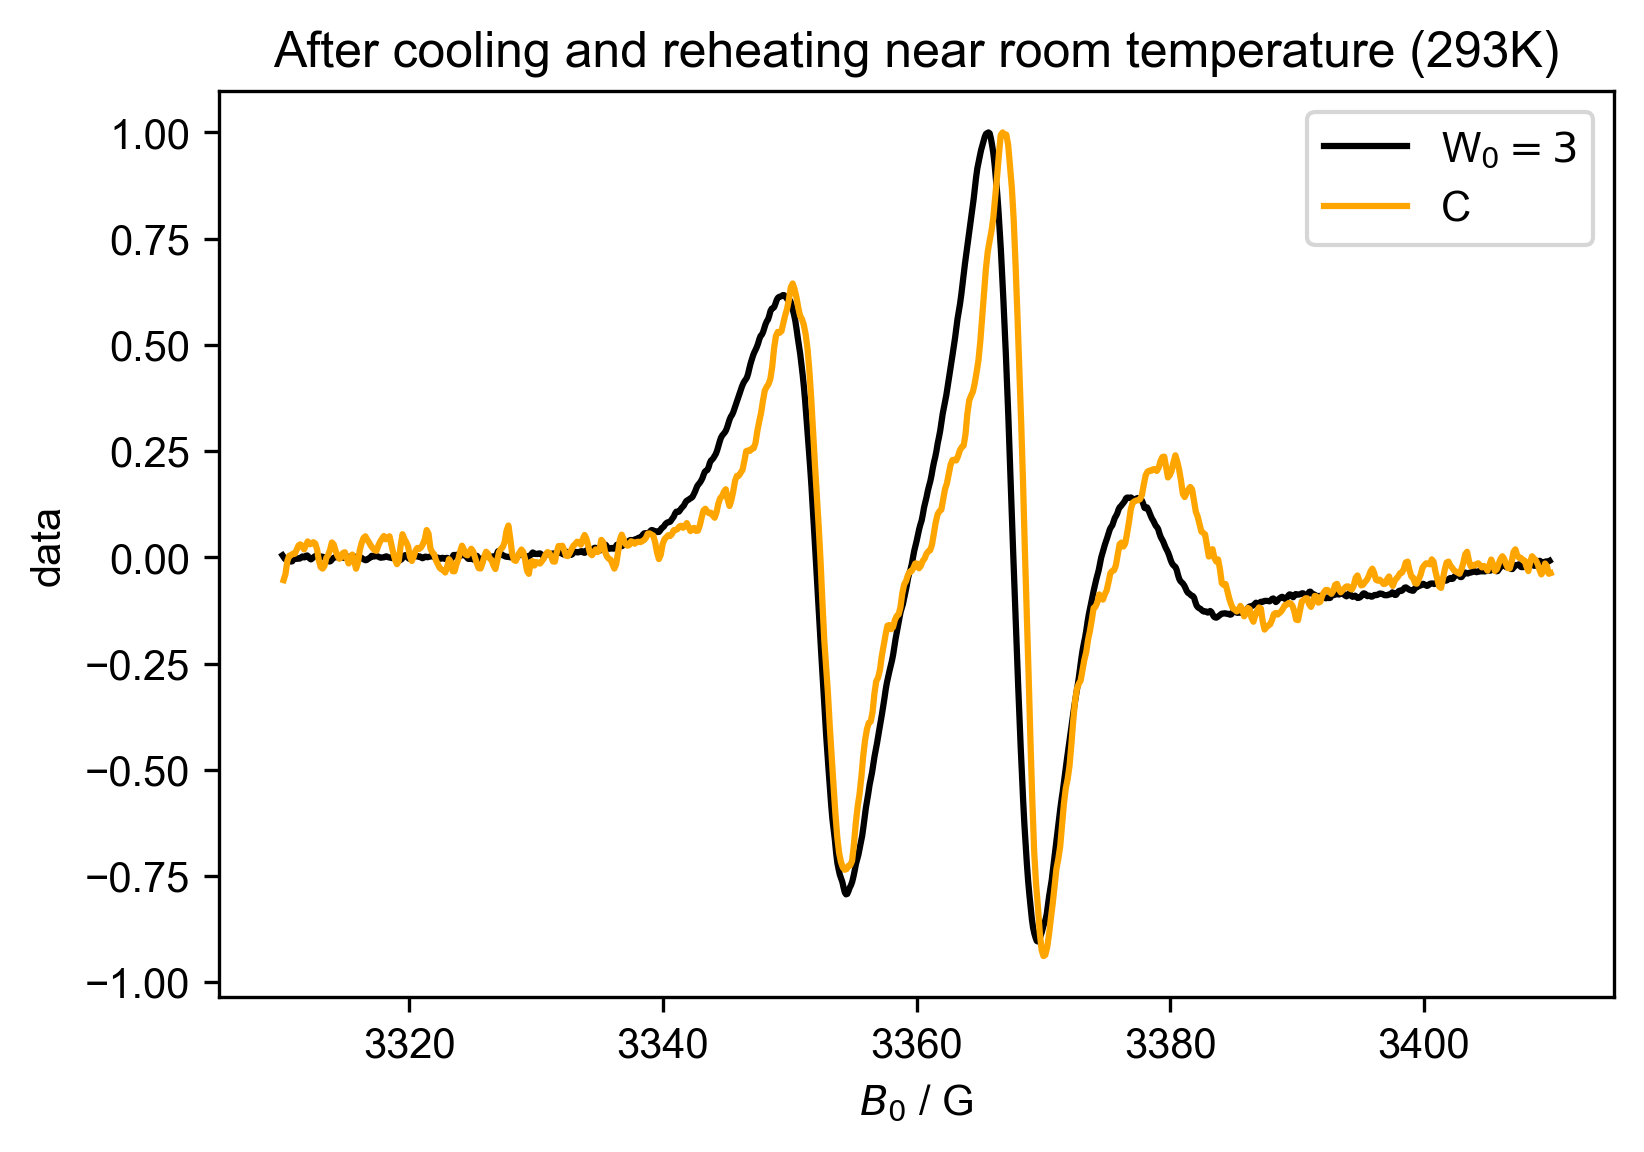

In [19]:
#Normalized
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "W$_0=3$", color="black")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "C", color="orange")
title("After cooling and reheating near room temperature (293K)")
legend()

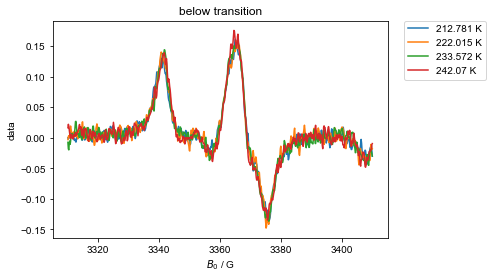

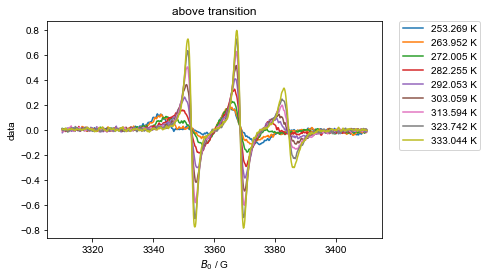

In [16]:
#heating run2
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

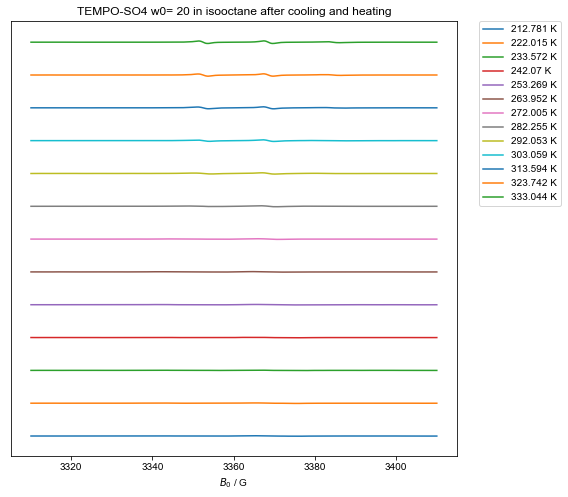

In [17]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO4 w0= 20 in isooctane after cooling and heating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += 20
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

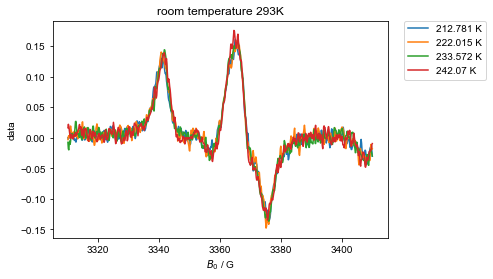

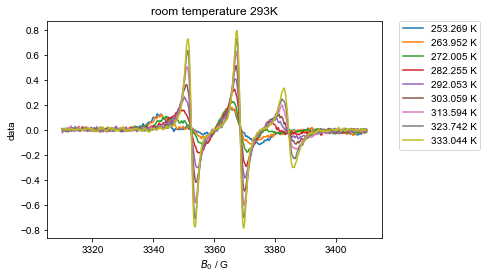

In [18]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title("room temperature 293K")
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot: